<a href="https://colab.research.google.com/github/IvanIri/Aprendizaje-Automatico-2/blob/main/TP2_clasifi_audio_IvanIrigoyen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## TP2: clasificación de audio y reconocimiento de habla

Iván Irigoyen

AA2

### Tutorial A: Clasificación de audio

In [1]:
# Importación de bibliotecas

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import Dataset
import torchaudio
import pandas as pd
import numpy as np

Configuramos el entorno de Colab para utilizar las redes neuronales de PyTorch con GPU T4, ya que esto nos otorga potencia para la ejecución del entrenamientos y pruebas.

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Dispositivo: cuda
GPU: Tesla T4


Importamos el conjunto de datos para entrenar nuestra red. Los datos se obtienen de la pagina "https://urbansounddataset.weebly.com" la cual contiene 10 clases de audio con más de 8000 muestras de sonido.

Una vez extraido el conjunto de datos lo analizaremos en el formato CSV que proporciona información de los archivos de sonido individualmente. Luego con la biblioteca de pandas iteraremos entre los archivos.

Cambie la forma en que carga el archivo por una con la que estoy más acostumbrado a utilizar.

In [3]:
# Cargamos el archivo de audio

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import tarfile
import os

# Ruta del archivo comprimido
ruta_tar = '/content/drive/MyDrive/Carrera Cs. Datos/Aprendizaje Auto 2/UrbanSound8K.tar.gz'

# Carpeta donde vamos a descomprimir
destino = '/content/'

# Descomprimir
with tarfile.open(ruta_tar, 'r:gz') as tar:
    tar.extractall(path=destino, filter='data')

print("Dataset descomprimido correctamente")

Dataset descomprimido correctamente


In [5]:
ruta = '/content/UrbanSound8K'
ruta_csv = f'{ruta}/metadata/UrbanSound8K.csv'

print("¿Existe la carpeta?", os.path.isdir(ruta))
print("¿Existe el CSV?", os.path.isfile(ruta_csv))
print("Ruta del CSV:", ruta_csv)

¿Existe la carpeta? True
¿Existe el CSV? True
Ruta del CSV: /content/UrbanSound8K/metadata/UrbanSound8K.csv


In [6]:
csvData = pd.read_csv(ruta_csv)

print(csvData.iloc[0, :])

slice_file_name    100032-3-0-0.wav
fsID                         100032
start                           0.0
end                        0.317551
salience                          1
fold                              5
classID                           3
class                      dog_bark
Name: 0, dtype: object


Entre las 10 clases de audios disponibles en UrbanSound8K vamos a utilizar 2 archivos, el primero contiene musica callejera y el segundo de un aire acondicionado.

In [7]:
import IPython.display as ipd

display(ipd.Audio(f'{ruta}/audio/fold1/108041-9-0-5.wav'))

display(ipd.Audio(f'{ruta}/audio/fold5/100852-0-0-19.wav'))

### Prepración de los datos

Creamos una clase que contenedora para el conjunto de datos, utilizando "torch.utils.data.Dataset", la cual se encarga de cargas los archivos y realizar los pasos de preparación necesarios. El dataset esta compuesto por 10 carpetas, usaremos los datos de 9 de estas para entrenar la red, mientras que la carpeta restante se utilizará para realizar las pruebas.
Al inicializarse, esta clase contenedora almacenara los nombres de los archivos, sus etiquetas y los numeros de carpeta que correspondientes a los archivos de audio presentes en la lista de carpetas dada.

El proceso de carga y preparación propiamente dicho tendrá lugar dentro de la funcion de acceso "__getitem__".

En "__getitem__", usamos "torchaudio.load()" para convertir los archivos WAV en tensores. "torchaudio.load()" devuelve una tupla que contiene el tensores recién creado junto con la frecuencia de muestreo del archivo de audio. Dado que el dataset utilizada 2 canales de audio, utilizaremos "torchaudio.transforms.DownmixMono()" para convertir los datos en un solo canal. Después tenemos que preparar los datos de audio. La red que se construira requiere de un tamaño de entrada de 32.000, mientras que la mayoria de los archivos contiene bastante mas de 100.000 muetras.

Dado que los audios que vamos a usar estan muestreados a 44,1 kHz, 32k de muestras solo cubren aprox 700 milisegundos, entonces, al reducir la frecuencia de muestreo (*downsampling*) a unos 8kHz, podemos representar 4 segundos de audio utilizando esas 32k de muestras.

Esta reducción se logra tomando 1 de cada 5 muestras del tensor del audio original. No todos los tensores de audio tienen la longitud suficiente para soportar este proceso, por lo que sera necesario rellenarlos con ceros (*padding*). La longitud minima que no requiere relleno es de 160.000 muestras.

Lo anterior quedo viejo, pero lo mantengo por q son los comentarios originales traducidos y resumidos.

### Cambios en el codigo realizados:

Realice una serie de cambios ya que no funcionaba el codigo.

La función "DownmixMono()" ya no esta disponible en la versión de "torchaudio" que utilizo. Fue reemplazado por "soundData.mean(dim=0, keepdim=True)", que calcula el promedio de los canales de audio para convertirlo en una señal de un unico canal.

Se modifico la instrucción original de carga del soundData, esto para permitir obtener directamente el tensor que contiene las muestras del audio y su frecuencia de muestreo, usando la sintaxis actual de Torchaudio.

Se reemplazo el metodo de selección de una de cada 5 muestras para reducir la cantidad de datos. Esto se reemplazo por "torchaudio.functional.resample()", el cual convierte la frecuencia original a 8000hz.

También realice cambios en las rutas y la condición para el uso de la GPU.

In [8]:
class UrbanSoundDataset(Dataset):
# Clase para el conjunto de datos UrbanSound8K.
    # Listo de argumentos
    #  Ruta del archivo CSV
    #  Ruta de los archivos de audio
    #  Lista de carptas a usar en el conjunto de datos

    def __init__(self, csv_path, file_path, folderList):
        csvData = pd.read_csv(csv_path)
        # Inicio de la lista pra almacenar los nombres, etiquetas y numero de carpeta
        self.file_names = []
        self.labels = []
        self.folders = []
        # Recorre las entradas del CSV y añade unicamente las que provengan de carpetas
        # incluidas en la lista de carpetas
        for i in range(0,len(csvData)):
            if csvData.iloc[i, 5] in folderList:
                self.file_names.append(csvData.iloc[i, 0])
                self.labels.append(csvData.iloc[i, 6])
                self.folders.append(csvData.iloc[i, 5])

        self.file_path = file_path
        self.folderList = folderList

    def __getitem__(self, index):

        # Construir la ruta del archivo
        path = os.path.join(
            self.file_path,
            f"fold{self.folders[index]}",
            self.file_names[index]
        )

        # Cargar audio
        soundData, sample_rate = torchaudio.load(path)

        # Convertir a mono
        if soundData.shape[0] > 1:
            soundData = soundData.mean(dim=0, keepdim=True)

        # Remuestrear a 8000 Hz
        if sample_rate != 8000:
            soundData = torchaudio.functional.resample(
                soundData, sample_rate, 8000
            )

        # Ajustar duración a 4 segundos (32000 muestras)
        soundData = soundData[:, :32000]

        if soundData.shape[1] < 32000:
            soundData = torch.nn.functional.pad(
                soundData,
                (0, 32000 - soundData.shape[1])
            )

        return soundData, self.labels[index]

    def __len__(self):
        return len(self.file_names)


csv_path = '/content/UrbanSound8K/metadata/UrbanSound8K.csv'
file_path = '/content/UrbanSound8K/audio/'

train_set = UrbanSoundDataset(csv_path, file_path, range(1,10))
test_set = UrbanSoundDataset(csv_path, file_path, [10])
print("Train set size: " + str(len(train_set)))
print("Test set size: " + str(len(test_set)))

kwargs = {'num_workers': 1, 'pin_memory': True} if device.type == 'cuda' else {} # Necesario para usar el dataset en la GPU

train_loader = torch.utils.data.DataLoader(train_set, batch_size = 128, shuffle = True, **kwargs)
test_loader = torch.utils.data.DataLoader(test_set, batch_size = 128, shuffle = True, **kwargs)

Train set size: 7895
Test set size: 837


### Definición de la red neuronal

Para este trabajo usaremos una red neuronal convolucional (CNN) para procesar los datos de audio en bruto. Aunque normalmente se aplican transformaciones más avanzadas a los datos de audio, las CNN puede usare para procesar los datos en bruto con gran precisión. La arquitectura especifica se basa en el modelo M5, descripto en https://arxiv.org/pdf/1610.00087.pdf.

Un aspecto fundamental en los modelos que procesa audio en bruto es el campo receptivo de los filtros de su primera capa. El primer filtro de nuestro modelo tiene una longitud de 80, por lo tanto, al procesar audio muestreado a 8kHz, el campo receptivo es de aprox 10 ms.

Este tamaño es similar utilizado en aplicaciones de procesamiento de voz, las cuales suelen emplear campos receptivos de entre 20 ms y 40 ms.

### Cambios en el codigo realizados:

Se reemplazó AvgPool1d(30) por AdaptiveAvgPool1d(1), permitiendo reducir automáticamente la dimensión temporal de los datos a un único valor por canal.

Además, se sustituyó permute(0, 2, 1) por squeeze(-1) para eliminar la dimensión innecesaria y obtener una salida de tamaño [batch_size, 10], correspondiente a las 10 clases del dataset UrbanSound8K.

Finalmente, se ajustó F.log_softmax(x, dim=1) para calcular las probabilidades logarítmicas sobre las 10 clases.

In [9]:

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()

        self.conv1 = nn.Conv1d(1, 128, 80, 4)
        self.bn1 = nn.BatchNorm1d(128)
        self.pool1 = nn.MaxPool1d(4)

        self.conv2 = nn.Conv1d(128, 128, 3)
        self.bn2 = nn.BatchNorm1d(128)
        self.pool2 = nn.MaxPool1d(4)

        self.conv3 = nn.Conv1d(128, 256, 3)
        self.bn3 = nn.BatchNorm1d(256)
        self.pool3 = nn.MaxPool1d(4)

        self.conv4 = nn.Conv1d(256, 512, 3)
        self.bn4 = nn.BatchNorm1d(512)
        self.pool4 = nn.MaxPool1d(4)

        # Reduce la dimensión temporal a 1
        self.avgPool = nn.AdaptiveAvgPool1d(1)

        # Clasificación en 10 categorías
        self.fc1 = nn.Linear(512, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(self.bn1(x))
        x = self.pool1(x)

        x = self.conv2(x)
        x = F.relu(self.bn2(x))
        x = self.pool2(x)

        x = self.conv3(x)
        x = F.relu(self.bn3(x))
        x = self.pool3(x)

        x = self.conv4(x)
        x = F.relu(self.bn4(x))
        x = self.pool4(x)

        x = self.avgPool(x)

        # Elimina la dimensión temporal
        x = x.squeeze(-1)

        # Capa de clasificación
        x = self.fc1(x)

        return F.log_softmax(x, dim=1)


model = Net().to(device)
print(model)

Net(
  (conv1): Conv1d(1, 128, kernel_size=(80,), stride=(4,))
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(128, 128, kernel_size=(3,), stride=(1,))
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv1d(128, 256, kernel_size=(3,), stride=(1,))
  (bn3): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv4): Conv1d(256, 512, kernel_size=(3,), stride=(1,))
  (bn4): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool4): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (avgPool): AdaptiveAvgPool1d(output_size=1)
  (fc1): L

Utilizaremos el optimizador Adam con una decadencia de pesos (*weight decay*) establecida en 0,0001. Primero realizaremos el entrenamiento con una tasa de aprendizaje de 0,01, pero emplearemos un planificador (*scheduler*) para reducir a 0,001 durante el proceso de entrenamiento.

In [10]:
optimizer = optim.Adam(model.parameters(), lr = 0.01, weight_decay = 0.0001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size = 20, gamma = 0.1)

### Entrenamiento y evaluación de la red neuronal

Definimos una función de entrenamiento que introduzca nuestros datos de entrenamiento al modelo y lleve a cabo el paso hacia atras (backward pass) y los pasos de optimización.

### Cambios en el codigo realizados:

Se eliminó output.permute(1, 0, 2), ya que la CNN ahora devuelve directamente un tensor de dimensiones [batch_size, 10], correspondiente a las predicciones de las 10 clases.

También se modificó el cálculo de la pérdida, reemplazando F.nll_loss(output[0], target) por F.nll_loss(output, target), dado que ya no es necesario seleccionar una dimensión adicional.

Finalmente, se incorporó loss.item() para mostrar el valor numérico de la pérdida durante el entrenamiento.

In [11]:
def train(model, epoch):
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        data = data.to(device)
        target = target.to(device)
        data = data.requires_grad_() # Establece "requires_grad" en "True" para el entrenamiento
        output = model(data)
        loss = F.nll_loss(output, target)  # La CNN devuelve [batch_size, 10]
        loss.backward()
        optimizer.step()
        if batch_idx % log_interval == 0: # Muestra las estadisticas de entrenamiento
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))

Ahora que contamos con una función de entrenamiento necesitamos crear una para evaluar la precisión de las redes. Configuremos el modelo en modo "eval()" y luego, realizaremos la inferencia sobre el conjunto de datos de prueba.

Al llamar a "eval()", la variable de entrenamiento de todos los modulos de las red se establece en "false". Ciertas capas, como las de normalización por lotes (*batch normalization*) y las de *dropout*, se comportan de forma diferente durante el entrenamiento, por lo que este paso resulta fundamental para obtener resultados correctos.

### Cambios en el codigo realizados:

Se eliminó output.permute(1, 0, 2), ya que el modelo devuelve directamente un tensor de dimensiones [batch_size, 10].

Además, se modificó output.max(2)[1] por output.max(1)[1], permitiendo identificar la clase con mayor probabilidad para cada audio.

Finalmente, se incorporó torch.no_grad() para desactivar el cálculo de gradientes durante la evaluación, optimizando el uso de memoria y recursos.

In [12]:
def test(model, epoch):
    model.eval()
    correct = 0

    with torch.no_grad():
        for data, target in test_loader:
            data = data.to(device)
            target = target.to(device)
            output = model(data)

            pred = output.max(1)[1] # Obtiene el índice de log-probabilidad máxima
            correct += pred.eq(target).cpu().sum().item()
        print('\nTest set: Accuracy: {}/{} ({:.0f}%)\n'.format(
            correct, len(test_loader.dataset),
            100. * correct / len(test_loader.dataset)))

Por ultimo, podemos entrenar y evaluar la red.

Entrenaremos la red durante 10 epocas, luego reduciremos la tasa de aprendizaje y la entrenaremos durante otras 10 epocas. La red se evaluara tras cada epoca para observar como varia la precisión durante el entrenamiento.

### Cambios en el codigo realizados:

Se trasladó scheduler.step() al final de cada época, después de ejecutar las funciones de entrenamiento y evaluación, respetando el orden recomendado por PyTorch para actualizar la tasa de aprendizaje.

Además, se eliminó el mensaje que indicaba un cambio de learning rate en la época 31, ya que la configuración actual de StepLR establece una reducción cada 20 épocas.

De esta manera, el modelo se entrena durante 40 épocas, utilizando una tasa de aprendizaje inicial de 0.01 que se reduce a 0.001 a partir de la época 21.

In [13]:
log_interval = 20
for epoch in range(1, 41):

    train(model, epoch)
    test(model, epoch)

    scheduler.step()

Train Epoch: 1 [0/7895 (0%)]	Loss: 2.309881
Train Epoch: 1 [2560/7895 (32%)]	Loss: 1.951639
Train Epoch: 1 [5120/7895 (65%)]	Loss: 1.855248
Train Epoch: 1 [7680/7895 (97%)]	Loss: 1.657179

Test set: Accuracy: 201/837 (24%)

Train Epoch: 2 [0/7895 (0%)]	Loss: 1.782638
Train Epoch: 2 [2560/7895 (32%)]	Loss: 1.583443
Train Epoch: 2 [5120/7895 (65%)]	Loss: 1.481852
Train Epoch: 2 [7680/7895 (97%)]	Loss: 1.267418

Test set: Accuracy: 341/837 (41%)

Train Epoch: 3 [0/7895 (0%)]	Loss: 1.683540
Train Epoch: 3 [2560/7895 (32%)]	Loss: 1.527206
Train Epoch: 3 [5120/7895 (65%)]	Loss: 1.410317
Train Epoch: 3 [7680/7895 (97%)]	Loss: 1.079347

Test set: Accuracy: 374/837 (45%)

Train Epoch: 4 [0/7895 (0%)]	Loss: 1.262418
Train Epoch: 4 [2560/7895 (32%)]	Loss: 1.123700
Train Epoch: 4 [5120/7895 (65%)]	Loss: 1.212141
Train Epoch: 4 [7680/7895 (97%)]	Loss: 1.213199

Test set: Accuracy: 390/837 (47%)

Train Epoch: 5 [0/7895 (0%)]	Loss: 1.103271
Train Epoch: 5 [2560/7895 (32%)]	Loss: 1.039011
Train Epoch:

### Conclusión

Si se entrena utilizando 9 carpetas, la red debería de alcanzar una precisión superior al 50% al finalizar el proceso de entrenamiento. Entrenar con un menor numero de carpetas hará que la precisión global sea menor, aunque puede resultar util si los tiempos de ejecución largos son un problema.

Es posible logar una mayor precisión utilizando CNN más profundas, a a costo de un mayor consumo de memoria.

Para aplicaciones de audio más avanzadas, como el reconocimiento de voz se suelen utilizar redes neuronales recurrentes (RNN). Asimismo, existen otros metodos de pre-procesamiento de datos, como la obtención de los coeficientes cepstrales en las frencuencias de Mel (MFCC), que permiten reducir el tamaña del conjunto de datos.

## Mi conclusión:

El modelo funciono bastante bien en general, la primera epoca había dado como resultado un accurancy de 38% el cual epoca tras epoca fue mejorando hasta alcanzar el maximo en la epoca 25, donde fue de un 72%. Luego comienzan probablemente un sobreajuste y el accurancy comienza a caer, hasta alcanzar un 66% en la ultima epoca, la 40.

Otra cosa a destacar es que a partir de la epoca 21 se observa una mejora y una mayor estabilidad en los resultados, coincidiendo con la reducción de la tasa de aprendizaje de 0,01 a 0,001.

## Tutorial B: Reconocimiento de voz

### Reconocimiento de voz con Wav2Vec2

Descripción general:

El proceso de reconocimiento de voz funciona de la siguiente manera:

1: Extraer las caracteristicas acusticas de la forma de onda del audio.
2: Estimar la clase de las caracteristicas acusticas, frame a frame (o segmento a segmento)
3: Generar hipotesis a partir de la secuencia de probabilidades de las clases.

Torchaudio ofrece un acceso sencillo a pesos pre-entrenados y a información asociada, como la frecuencia de muestreo esperada y las etiquetas de clase.
Estos elementos se encuentran agrupados y disponibles a traves del modulo :py:mod:'torchaudio.pipelines'.

In [1]:
# Preparación

import torch
import torchaudio

print(torch.__version__)
print(torchaudio.__version__)

torch.random.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

2.11.0+cpu
2.11.0+cpu
cpu


In [2]:
import IPython
import matplotlib.pyplot as plt
from torchaudio.utils import _download_asset

SPEECH_FILE = _download_asset("tutorial-assets/Lab41-SRI-VOiCES-src-sp0307-ch127535-sg0042.wav")

100%|██████████| 106k/106k [00:00<00:00, 4.99MB/s]


Creación del pipeline:

Primero creamos un modelo Wav2Vec2 que realice la extración de caracteristicas y la clasificación.

En 'torchaudio' existen 2 tipos de pesos pre-entrenados para Wav2Vec2:
Aquellos que han sido ajustados (fine-tuned) para tareas de reconocimiento automatico del habla (ASR) y los que no lo han sido.

Los modelos Wav2Vec2 (y HuBERT) se entrenan mediante un enfoque auto-supervisado (self-supervised). Primero se entrena utilizando unicamente audio para el aprendizaje de representaciones y luego se ajustan para una tarea especifica mediante el uso de etiquetas adicionales.
Los pesos pre-entrenados que no han sido ajustados pueden adaptase para otras tareas posteriores (downstream tasks), aunque este tutorial no abarda el proceso.

Acá utilizamos :py:mod:'torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H'.

En ':py:mod: torchaudio.pipelines' hay disponibles varios modelos pre-entrenados.

Sobre como han sido entrenados:
El objeto "bundle" proporciona la interfaz necesaria para instaciar el modelo, ademas de otra información relevante. la frecuencia de muestreo (sampling rate) y las etiquetas de clase pueden obtenerse de la siguiente manera:



In [3]:
bundle = torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H

print("Sample Rate:", bundle.sample_rate)

print("Labels:", bundle.get_labels())

Sample Rate: 16000
Labels: ('-', '|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z')


El modelo se puede construir de la siguiente manera:

Este proceso automaticamente obtendra los pesos pre-entrenados y los cargará en el modelo.

In [4]:
model = bundle.get_model().to(device)

print(model.__class__)


Downloading: "https://download.pytorch.org/torchaudio/models/wav2vec2_fairseq_base_ls960_asr_ls960.pth" to /root/.cache/torch/hub/checkpoints/wav2vec2_fairseq_base_ls960_asr_ls960.pth


100%|██████████| 360M/360M [00:05<00:00, 69.0MB/s]


<class 'torchaudio.models.wav2vec2.model.Wav2Vec2Model'>


Carga de datos:

Usamos los datos de voz del 'conjunto de datos VOiCES <https://iqtlabs.github.io/voices/>`__, que cuenta con una licencia Creative Commos BY 4.0.

In [5]:
IPython.display.Audio(SPEECH_FILE)


Para cargar datos, utilizamos :py:func:'torchaudio.load'.

si la ferncuencia de muestreo difiere de la esperada por el flujo de procesamiento (pipeline), podemos emplear :py:func:'torchaudio.functional.resample' para realizar el re-muestreo.

Nota:
:py:func:'torchaudio.functional.resample' también funciona como tensores en CUDA.

Si se requiere realizar remuestreos multiples veces sobre el mismo conjunto de frecuencia de muestro el uso de :py:func:'torchaudio.functional.resample' puede mejorar el rendimiento.

In [6]:
waveform, sample_rate = torchaudio.load(SPEECH_FILE)
waveform = waveform.to(device)

if sample_rate != bundle.sample_rate:
    waveform = torchaudio.functional.resample(waveform, sample_rate, bundle.sample_rate)

Extracción de caracteristicas acusticas

El siguiente paso consiste en extraer las caracteristicas acusticas del audio.

Nota:
Los modelos Wav2Vec2 ajustados para tareas de reconocimiento automatico del habla (ASR) puede realizar la extración de caracteristicas y la clasificación en un solo paso. Sin embargo, para los fines del tutorial mostraremos como llevar a cabo la extración de caracteristica.

In [7]:
with torch.inference_mode():
    features, _ = model.extract_features(waveform)

Las caracteristicas devueltas constituyen una lista de tensores. Cada tensor es la salida de una capa de transformación.

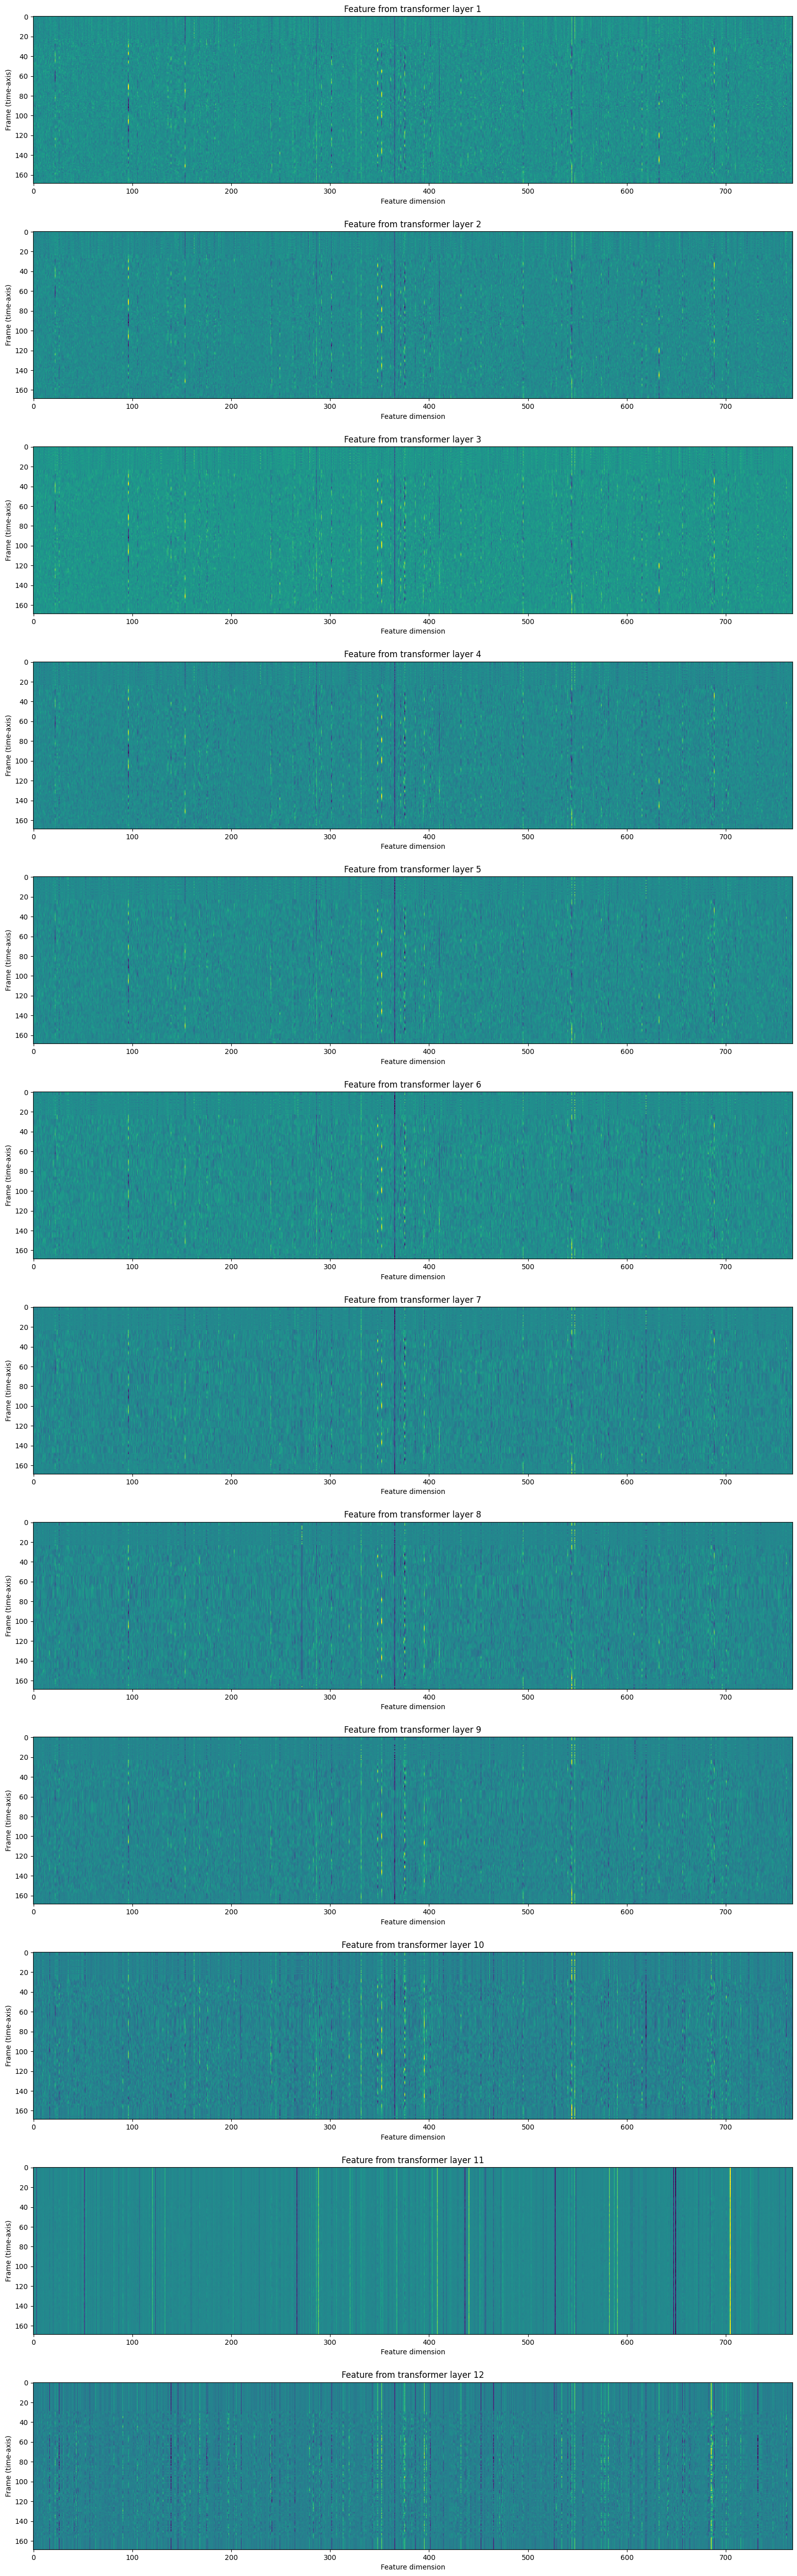

In [8]:
fig, ax = plt.subplots(len(features), 1, figsize=(16, 4.3 * len(features)))
for i, feats in enumerate(features):
    ax[i].imshow(feats[0].cpu(), interpolation="nearest")
    ax[i].set_title(f"Feature from transformer layer {i+1}")
    ax[i].set_xlabel("Feature dimension")
    ax[i].set_ylabel("Frame (time-axis)")
fig.tight_layout()

Clasificación de caracteristicas:

Una vez extraidas las caracteristicas acusticas, el siguiente paso consiste en clasificarlas en un conjunto de categorias.

El modelo Wav2Vec2 proporciona un metodo para realizar la extración y la clasificación de caracteristicas en un solo paso.

In [9]:
with torch.inference_mode():
    emission, _ = model(waveform)

El resultado se presenta en forma de logits, No esta en forma de probabilidad.

Visualización:

Class labels: ('-', '|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z')


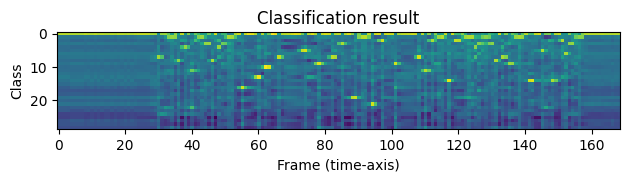

In [10]:
plt.imshow(emission[0].cpu().T, interpolation="nearest")
plt.title("Classification result")
plt.xlabel("Frame (time-axis)")
plt.ylabel("Class")
plt.tight_layout()
print("Class labels:", bundle.get_labels())

Podemos observar que existen indicios claros de determinadas etiquetas a lo largo de la linea temporal.

Generación de transcripciones:

A partir de la secuencia de probabilidades de las etiquetas, el objetivo es generar transcripciones.
El proceso para generar las hipotesis suele llamarse "decodificación".

La decodificación es más compleja que una simple clasificación, ya que la decisión en un instante de tiempo determinado puede verse influida por las observaciones circundantes.

Por ejemplo, consideremos las palabras "nigth" y "knight". aunque sus distrubuciones de probabilidad a priori sean distintas (en conversaciones normales "night" aparece mucho más frecuentemente que "knight"), para generar correctamente las transcripciones que incluyan "knight" como por ejemplo en "knight with a sword", el proceso de decodificación debe posponer la decision final hasta disponer de suciente contexto.

Existen diversas tecnicas de decodificación, las cuales suelen requerir recursos externos, como diccionarios de palabras y modelos de lenguaje.

En este tutorial, por motivos de simplicidad, utilizaremos la decodificacion "voraz" (greedy decoding), que no depende de dichos componentes externos.  Simplemente selecciona la mejor hipotesis en cada instante de tiempo. Por tanto, no se emplea información contextual y solo es posible generar una unica transcripcion.

Comenzamos definiendo el algoritmo de decodificación voraz.

In [11]:
class GreedyCTCDecoder(torch.nn.Module):
    def __init__(self, labels, blank=0):
        super().__init__()
        self.labels = labels
        self.blank = blank

    def forward(self, emission: torch.Tensor) -> str:
        """Dada una secuencia de emisión sobre etiquetas, obtiene la mejor cadena.
        Argumentos:
          Emisión (Tensor): tensores Logit. forma `[num_seq, num_label]`.

        Devuelve:
          str: la transcripción resultante
        """
        indices = torch.argmax(emission, dim=-1)  # [num_seq,]
        indices = torch.unique_consecutive(indices, dim=-1)
        indices = [i for i in indices if i != self.blank]
        return "".join([self.labels[i] for i in indices])

Ahora crea el objeto decodificador y decodifica la transcripción.

In [12]:
decoder = GreedyCTCDecoder(labels=bundle.get_labels())
transcript = decoder(emission[0])


Comprobamos el resultado y escuchemos de nuevo el audio.

In [13]:
print(transcript)
IPython.display.Audio(SPEECH_FILE)

I|HAD|THAT|CURIOSITY|BESIDE|ME|AT|THIS|MOMENT|


El modelo ASR se ajusta mediante una funcion de perdida denominada 'Clasificación Temporal Conexionista' (CTC).

Los detalles de la función de perdida se explican acá: <https://distill.pub/2017/ctc/>`__.
En CTC, el token en blanco es un token especial que representa la repetición del simbolo anterior durante la decodificación, estos tokens simplemente se ignoran.

Conclusiones:

En este tutorial, hemos visto como utilizar ':py:class:`~torchaudio.pipelines.Wav2Vec2ASRBundle`' para realizar la extración de caracteristicas acusticas y el reconocimiento de voz.

Construir un modelo y obtener las emisiones requiere apenas dos lineas de codigo.

model = torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H.get_model()

emission = model(waveforms, ...)